# Habitable Zone Analysis

This notebook walks through the `habitable_zone.py` module: habitable zone (HZ) boundaries from **Kopparapu et al. (2014)**, and where known exoplanets sit relative to them.

The HZ edges are set by an effective stellar flux

$$S_{\rm eff} = S_{\rm eff,\odot} + aT_\star + bT_\star^2 + cT_\star^3 + dT_\star^4, \qquad T_\star = T_{\rm eff} - 5780\,{\rm K}$$

and the distance of each edge is $d = \sqrt{L_\star / S_{\rm eff}}$ AU, with $L_\star$ in solar units.

In [1]:
import warnings
import pandas as pd
from IPython.display import Image
import habitable_zone as hz

pd.set_option("display.float_format", "{:.4g}".format)

## 1. Sanity check: the Solar System

The conservative HZ runs from the runaway greenhouse limit to the maximum greenhouse limit. For the Sun, Kopparapu et al. (2014) give 0.95–1.67 AU.

In [2]:
hz.hz_limits(teff=5780, luminosity=1.0)

{'optimistic_inner': 0.7503752814845803,
 'conservative_inner': 0.950443247520335,
 'conservative_outer': 1.6760038078849773,
 'optimistic_outer': 1.7677669529663689}

## 2. Habitable zones of nearby planet hosts

Stellar parameters, with their sources, are in `data/stars.csv`. TRAPPIST-1 is slightly cooler than the 2600 K lower limit of the fits, so its limits are extrapolated and a warning is raised.

In [3]:
stars, planets = hz.load_catalogue()
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    star_df = hz.star_table(stars)
star_df[["star", "teff_k", "luminosity_lsun", "conservative_inner_au", "conservative_outer_au",
         "period_inner_days", "period_outer_days"]]

,star,teff_k,luminosity_lsun,conservative_inner_au,conservative_outer_au,period_inner_days,period_outer_days
0,Sun,5772,1,0.9509,1.677,338.7,793.3
1,Proxima Centauri,3050,0.00155,0.04098,0.08134,8.747,24.46
2,TRAPPIST-1,2566,0.000553,0.02463,0.04992,4.71,13.6
3,Kepler-442,4402,0.117,0.3476,0.6458,95.85,242.7
4,GJ 667C,3350,0.0137,0.1215,0.2377,26.92,73.67
5,Barnard's Star,3134,0.0035,0.06153,0.1216,14.69,40.84
6,TOI-700,3480,0.0233,0.1582,0.3075,35.62,96.58
7,Teegarden's Star,2904,0.00073,0.02817,0.05628,5.788,16.34


## 3. Where do the known planets sit?

For each planet we compute the insolation $S = L_\star / a^2$, the equilibrium temperature (Bond albedo 0.3, full heat redistribution) and the **HZ distance** of Kane & Gelino (2012), which is −1 at the inner edge and +1 at the outer edge.

In [4]:
planet_df = hz.planet_table(stars, planets)
planet_df

,planet,star,semi_major_axis_au,period_days,insolation_searth,t_eq_k,hz_distance,location
0,Venus,Sun,0.723,224.5,1.913,299.7,-1.628,too hot
1,Earth,Sun,1,365.2,1,254.8,-0.8648,conservative HZ
2,Mars,Sun,1.524,687.2,0.4306,206.4,0.5782,conservative HZ
3,Proxima Cen b,Proxima Centauri,0.0485,11.26,0.6589,229.6,-0.6274,conservative HZ
4,TRAPPIST-1 d,TRAPPIST-1,0.02227,4.051,1.115,261.9,-1.186,optimistic HZ
5,TRAPPIST-1 e,TRAPPIST-1,0.02925,6.097,0.6464,228.5,-0.6344,conservative HZ
6,TRAPPIST-1 f,TRAPPIST-1,0.03849,9.204,0.3733,199.2,0.09613,conservative HZ
7,TRAPPIST-1 g,TRAPPIST-1,0.04683,12.35,0.2522,180.6,0.7555,conservative HZ
8,Kepler-442 b,Kepler-442,0.409,122.3,0.6994,233,-0.5883,conservative HZ
9,GJ 667C c,GJ 667C,0.125,28.1,0.8768,246.6,-0.9392,conservative HZ


## 4. Figures

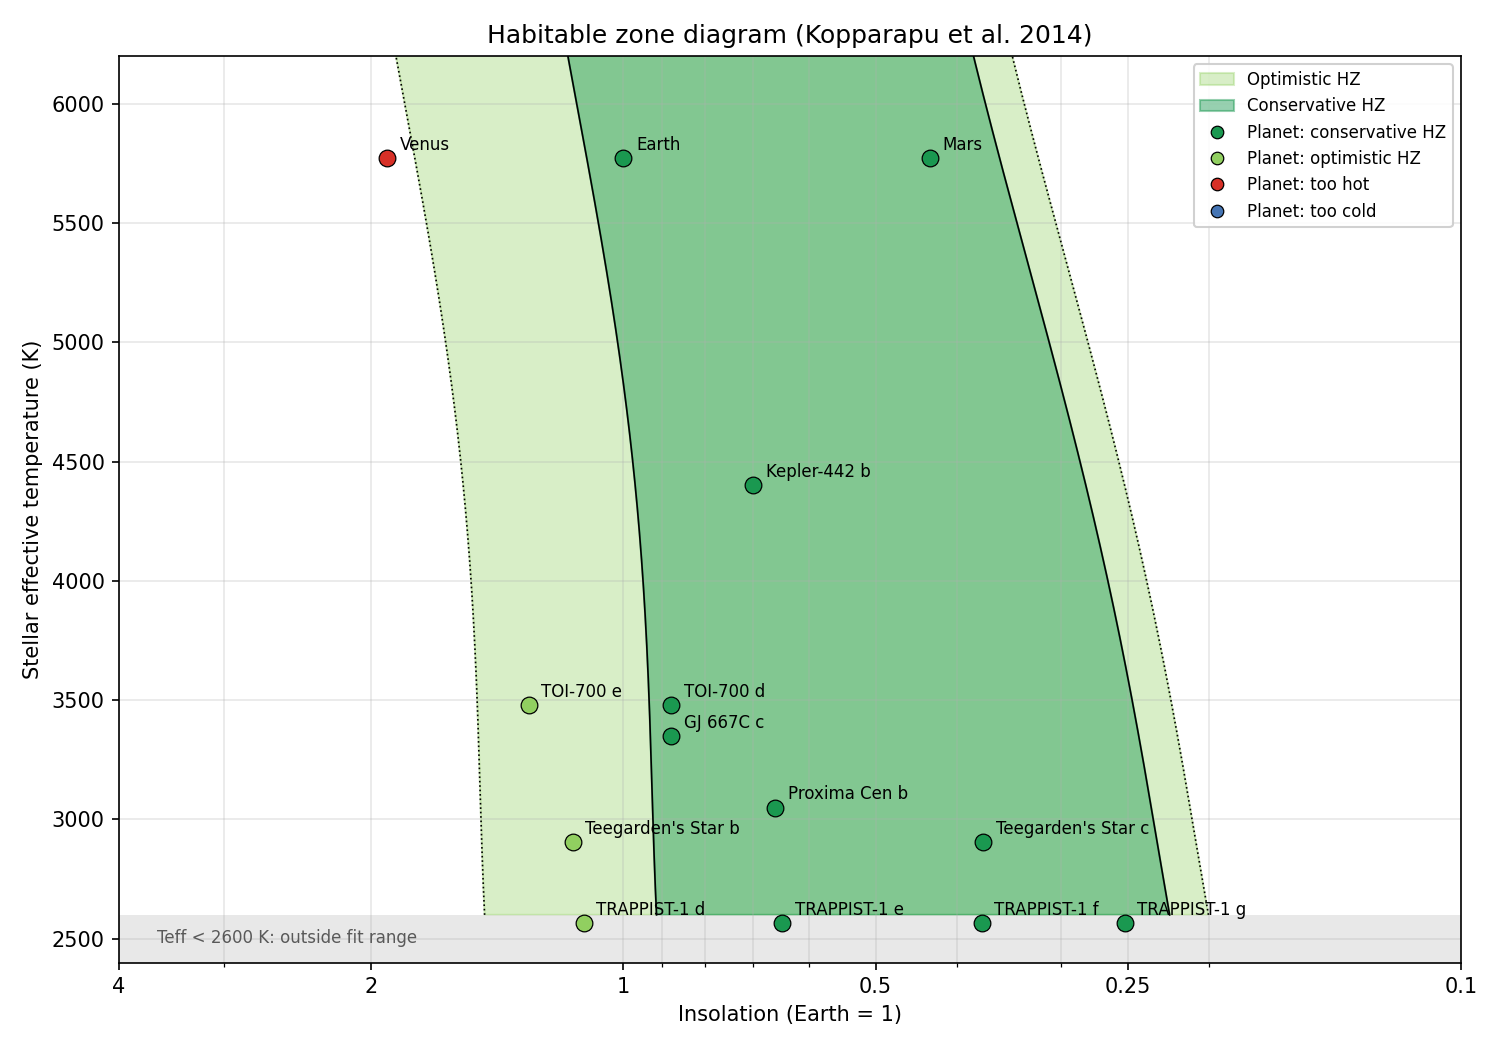

In [5]:
hz.plot_hz_diagram(stars, planet_df, "figures/hz_diagram.png")
hz.plot_systems(star_df, planet_df, "figures/hz_systems.png")
hz.plot_hz_comparison(star_df, planet_df, "figures/hz_comparison.png")
Image("figures/hz_diagram.png", width=800)

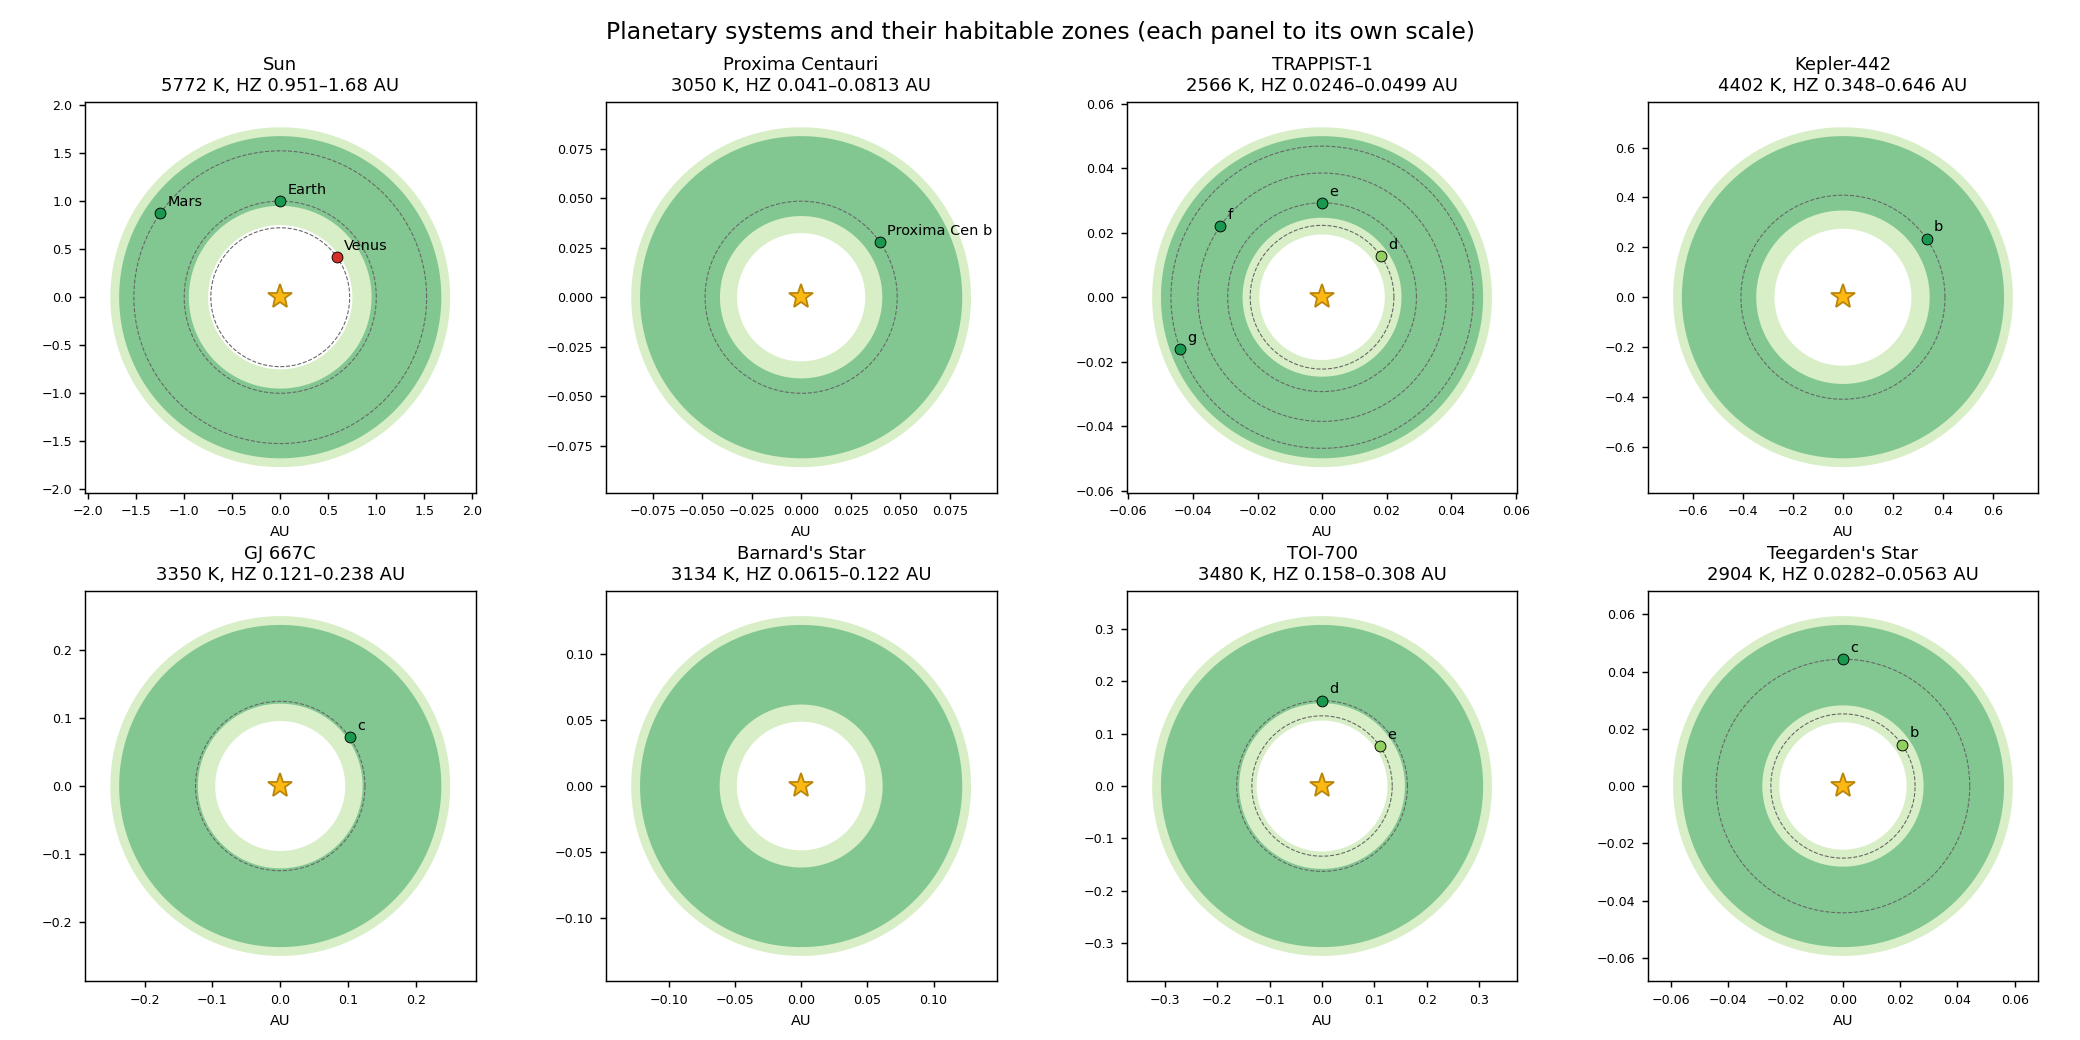

In [6]:
Image("figures/hz_systems.png", width=900)

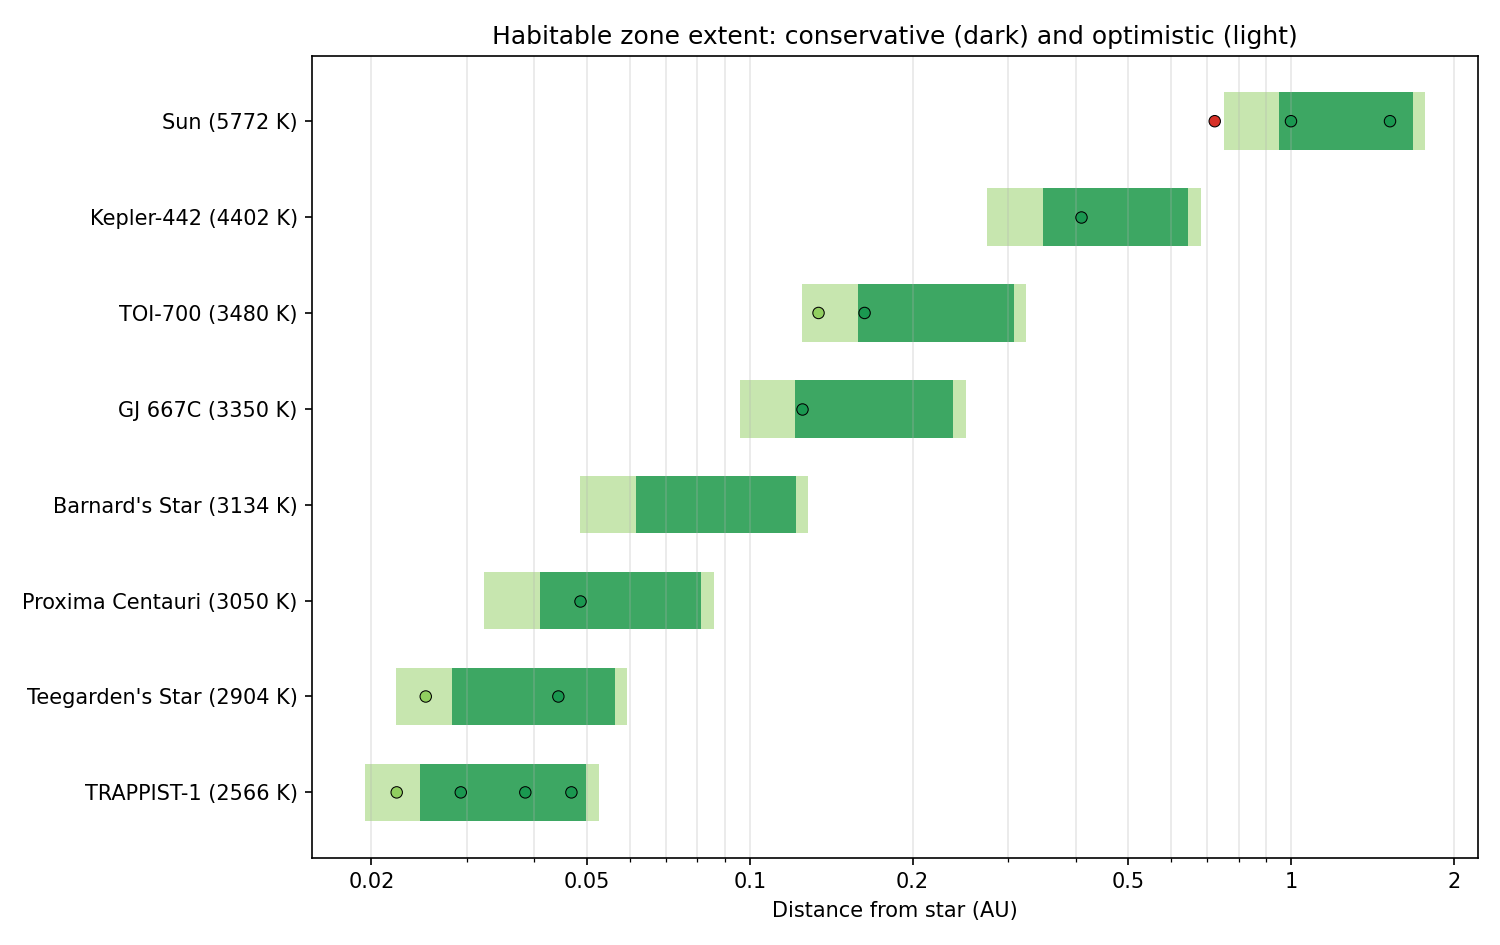

In [7]:
Image("figures/hz_comparison.png", width=800)

## 5. Your own star

Effect of planet mass on the inner edge: larger planets hold denser atmospheres and can sit closer to their star before entering a runaway greenhouse.

In [8]:
for m in (0.1, 1.0, 5.0):
    lim = hz.hz_limits(teff=3500, luminosity=0.02, planet_mass=m)
    print(f"{m:>4} M_earth: conservative HZ = {lim['conservative_inner']:.4f} - {lim['conservative_outer']:.4f} AU")

 0.1 M_earth: conservative HZ = 0.1553 - 0.2846 AU
 1.0 M_earth: conservative HZ = 0.1465 - 0.2846 AU
 5.0 M_earth: conservative HZ = 0.1414 - 0.2846 AU
